# Simulación de Tasas de Interés

Los modelos para calcular el precio de opciones que hemos presentado hasta ahora suponen que la distribución de probabilidad del subyacente es lognormal. 

Hay algunos modelos así que utilizan ampliamente para valorar instrumentos como caps, opciones de bonos europeos y opciones sobre swap europeos. Sin embargo, tienen limitaciones. No proporcionan una descripción de cómo evolucionan las tasas de interés a lo largo del tiempo. En consecuencia, no pueden utilizarse para la valoración de derivados de tipos de interés de tipo americano o notas estructuradas.

Este libro se analizan enfoques alternativos para superar estas limitaciones. Estos implican construir lo que se conoce como un modelo de estructura temporal. Este es un modelo que describe la evolución de todas las tasas de interés cupón cero. Este libro se centra en los modelos de estructura temporal construidos especificando el comportamiento de la tasa de interés a corto plazo, $r$.

Este libro se ocupa de modelar una única curva cero libre de riesgo. La tendencia hacia el descuento OIS significa que a menudo es necesario modelar dos curvas cero simultáneamente.  

# Antecedentes

La tasa a corto plazo libre de riesgo, $r_t$, en el tiempo $t$ es la tasa que se aplica a un período de tiempo infinitesimalmente corto en $t$. A veces se la denomina tasa corta instantánea.

Los precios de los bonos, los precios de las opciones y otros precios de derivados dependen únicamente del proceso seguido por $r$ en un mundo neutral al riesgo. El proceso para $r$ en el mundo real no se usa. En el mundo neutral al riesgo tradicional es un mundo en el que, en un período de tiempo muy corto entre $t$ y $t + \Delta t$, los inversionistas ganan en promedio $r_t \Delta t$. Todos los procesos para $r$ que se considerarán en este libro, excepto donde se indique lo contrario, son procesos en este mundo neutral al riesgo.

El valor en el tiempo $t$ de un derivado de tasa de interés que proporciona una
el pago de $f_T$ en el tiempo $T$ es:

$$ \mathbb{E}\left(e^{-\int_0^t r_s ds} f_T\right) $$

donde $r_s$ es el valor que toma la tasa instantanea al tiempo $s \in [t,T]$, y $\mathbb{E}$ denota el valor esperado en el mundo neutral al riesgo.

Denotamos como $P(t,T)$ como el precio en el tiempo $t$ de un bono cupón cero libre de riesgo que paga $1$ en el tiempo $T$. Entonces:

$$ P(t,T) = \mathbb{E}\left(e^{-\int_0^t r_s ds} \right) $$

Si $R(t,T)$ es la tasa de interés libre de riesgo compuesta continuamente en el tiempo $t$ por un plazo de
$T - t$, entonces:

$$ P(t,T) = e^{-R(t,T)(T-t)}, \qquad \text{o bien } R(t,T) = -\frac{1}{T-t}\ln P(t,T). $$

Esta ecuación permite obtener la estructura temporal de las tasas de interés en un momento dado a partir del valor de $r$ en ese momento y el proceso neutral al riesgo para $r$. Una vez que se ha definido el proceso para $r$, se puede determinar todo sobre la curva cero inicial y su evolución a lo largo del tiempo.

Supongamos que $r$ sigue la EDE:

$$ dr_t = m(t,r_t)dt + \sigma(t,r_t)dW_t $$

Del lema de Itô, cualquier función $f$ dependiente de $r$ sigue el proceso

$$ df_t = \left( \frac{\partial f}{\partial t} + m(t,r_t)\frac{\partial f}{\partial r} + \frac{1}{2}\sigma^2(t,r_t) \frac{\partial^2 f}{\partial r^2} \right)dt + \sigma(t,r_t) \frac{\partial f}{\partial r} dW_t$$

Debido a que estamos trabajando en el mundo neutral al riesgo tradicional, si el derivado no proporciona ingresos intermedios, este proceso debe tener la forma:

$$ df_t = r_t f_t dt + \cdots$$

de donde podemos obtener la representación en EDP:

$$ \frac{\partial f}{\partial t} + m(t,r_t)\frac{\partial f}{\partial r} + \frac{1}{2}\sigma^2(t,r_t) \frac{\partial^2 f}{\partial r^2} = r_t f_t. $$

Este es el equivalente de la EDP de Black-Scholes-Merton para derivados de tasa de interés. Una solución particular a la ecuación debe ser el precio del bono cupón cero $P(t,T)$, pues es función de $r$.

# Modelos de Equilibrio
Los modelos de equilibrio generalmente comienzan con supuestos sobre variables económicas y derivan un proceso para la tasa instantanea, $r$. Luego exploran qué implica el proceso para $r$ sobre los precios de los bonos, swaps y opciones sobre tasas de interés como caps, floors o swaptions.

En un modelo de equilibrio de un factor, el proceso para $r$ involucra solo una fuente de incertidumbre (i.e. un solo browniano). Por lo general, el proceso neutral al riesgo para la tasa corta se describe mediante un proceso Itô de la forma:

$$ dr_t = m(r_t)dt + \sigma(r_t)dW_t.$$

Se supone que el drift instantáne, $m$, y la desviación estándar instantánea, $\sigma$, son funciones de $r$, pero son independientes del tiempo. 

El supuesto de un solo factor no es tan restrictiva como podría parecer. Un modelo de un factor implica que todas las tasas se mueven en la misma dirección durante un intervalo corto de tiempo, pero no que todas se mueven en la misma cantidad. Por lo tanto, la forma de la curva cero puede cambiar con el paso del tiempo.

Los modelos más comunes en la industria son:

$$
\begin{eqnarray}
    m(r_t) &=& \mu r_t, \quad \sigma(r_t) = \sigma r_t \qquad \text{(Rendleman-Bartter)}\\
    m(r_t) &=& a(b-r_t), \quad \sigma(r_t) = \sigma \qquad \text{(Vasicek)}\\
    m(r_t) &=& a(b-r_t), \quad \sigma(r_t) = \sigma \sqrt{r_t} \qquad \text{(Cox-Ingersoll-Ross)}
\end{eqnarray}
$$

<a id='sec3'></a>
# CIR process

El proceso Cox-Ingersoll-Ross [CIR](https://en.wikipedia.org/wiki/Cox%E2%80%93Ingersoll%E2%80%93Ross_model) tiene la siguiente EDE: 

$$ dX_t = \kappa (\theta - X_t) dt + \sigma \sqrt{X_t} dW_t $$

Los parámetros son:
- $\kappa$ coeficiente de reversión a la media
- $\theta$ media a largo plazo
- $\sigma$ coeficiente de volatilidad

Si $2\kappa \theta > \sigma^2$ (condición de Feller), ¡el proceso siempre es estrictamente positivo!



Para poder hacer implementaciones numéricas de este proceso, se puede usar el siguiente método.

## Método de Euler-Maruyama

Dividimos el intervalo $[0,T]$ en 
$$0=t_0, t_1, ..., t_{n-1}, t_n=T.$$      

Podemos elegir puntos equidistantes $t_i$  de manera que $\Delta t = t_{i+1} - t_i = \frac{T}{N}$ para cada $1 \leq i \leq N$.

Entonces una EDE de Itô general como

$$
\begin{align*}
&dX_t = \mu(t,X_t) dt + \sigma(t, X_t) dW_t \\
&X_0 = 0
\end{align*}
$$

se puede aproximar como:

$$
\begin{align*}
& X_{i+1} = X_i + \mu(t_i,X_i) \Delta t + \sigma(t_i, X_i) \Delta W_i \\
&X_0 = 0
\end{align*}
$$

donde $X(t_i) = X_i$ y $W(t_i) = W_i$.     

Lo que necesitamos simular es $W_{i+1} - W_i = \Delta W_i \sim \mathcal{N}(0, \sqrt{\Delta t})$.

Si aplicamos este método al CIR tenemos:

$$ X_{i+1} = X_i + \kappa (\theta - X_i) \Delta t + \sigma \sqrt{X_i} \Delta W_i $$

A pesar de la presencia de la condición de Feller, cuando discretizamos el proceso, es posible que $X_i$ se vuelva negativo, creando problemas en la evaluación de la raíz cuadrada. Los métodos más comunes para superar este problema son:

1) $ X_{i+1} = X_i + \kappa (\theta - X_i) \Delta t + \sigma \sqrt{X_i^+} \Delta W_i $

2) $ X_{i+1} = X_i + \kappa (\theta - X_i^+) \Delta t + \sigma \sqrt{X_i^+} \Delta W_i $

3) $ X_{i+1} = X_i + \kappa (\theta - X_i) \Delta t + \sigma \sqrt{|X_i|} \Delta W_i $

4) $ X_{i+1} = |X_i + \kappa (\theta - X_i) \Delta t + \sigma \sqrt{X_i} \Delta W_i |$

donde `^+` indica la parte positiva.
Los métodos 1), 2) y 3) solo resuelven el problema de la raíz cuadrada, pero el proceso aún puede volverse negativo.
¡El método 4) evita esta posibilidad!

Aunque realmente la parte difícil es demostrar que cualquier de estos cambios no modifican el proceso cuando la norma de la partición tiende a cero.

Echemos un vistazo a la implementación del **método 4)**

In [4]:
import numpy as np
import scipy as scp
import scipy.stats as ss
import matplotlib.pyplot as plt
from statsmodels.graphics.gofplots import qqplot
from scipy.special import iv
from scipy.optimize import minimize

In [5]:
T = 3
N = 200001        # time steps 

np.linspace(0,T,N, retstep=True ) 

(array([0.000000e+00, 1.500000e-05, 3.000000e-05, ..., 2.999970e+00,
        2.999985e+00, 3.000000e+00]),
 1.5e-05)

In [6]:
%%time
np.random.seed(seed=123) 

N = 2001        # pasos en la partición del tiempo 
paths = 100000      # número de trayectorias que se desean
T = 3
T_vec, dt = np.linspace(0,T,N, retstep=True ) 

kappa = 4 # velocidad de reversión a la media
theta = 1 # media a largo plazo
sigma = 0.5  # coeficiente de difusión
std_asy = np.sqrt( theta * sigma**2 /(2*kappa) )   # std asintótica

X0 = 2  # valor inicial
X = np.zeros((paths,N))  # vector para contener las trayectorias
X[:,0] = X0  # todas las trayectorias inician con la misma condición inicial
W = ss.norm.rvs( loc=0, scale=np.sqrt(dt), size=(paths,N-1) )  # generamos las normales necesarias

# método 4 para simular el CIR
for t in range(0,N-1):
    X[:,t+1] = np.abs( X[:,t] + kappa*(theta - X[:,t])*dt + sigma * np.sqrt(X[:,t]) * W[:,t] )

#X_T = X[:,-1]    # valores de X al tiempo T
#X_1 = X[1,:]     # la primera trayectoria

CPU times: user 16.1 s, sys: 5.01 s, total: 21.2 s
Wall time: 23 s


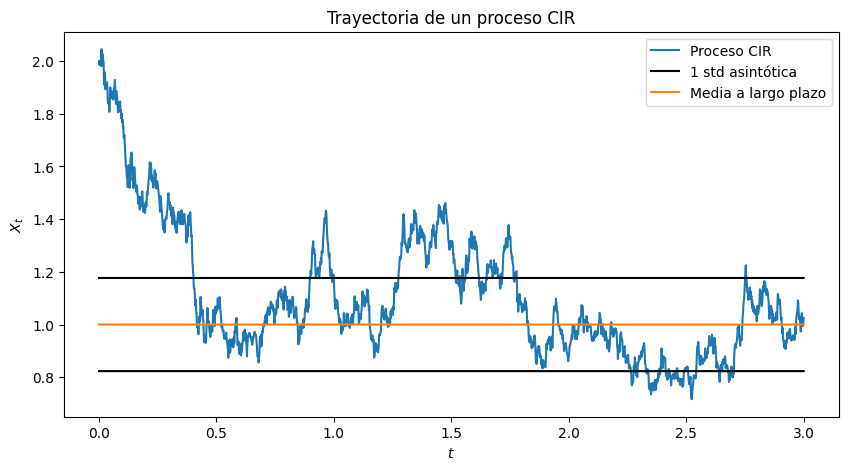

In [7]:
X_T = X[:,-1]    # valores de X al tiempo T
X_1 = X[4,:]     # alguna trayectoria

plt.figure(figsize=(10,5))
plt.plot(T_vec, X_1, label="Proceso CIR")
plt.plot(T_vec, (theta + std_asy)*np.ones_like(T_vec), label="1 std asintótica", color="black" )
plt.plot(T_vec, (theta - std_asy)*np.ones_like(T_vec), color="black" )
plt.plot(T_vec, theta*np.ones_like(T_vec), label="Media a largo plazo" )
plt.legend(loc="upper right"); plt.title("Trayectoria de un proceso CIR"); 
plt.xlabel(r"$t$")
plt.ylabel(r"$X_t$")
plt.show()

En el gráfico anterior se incluye la media y la desviación estándar a largo plazo:

$$ \lim_{t\to \infty} \mathbb{E}(X_t) \to \theta, $$    
$$ \lim_{t\to \infty} Var(X_t) \to \frac{\theta \sigma^2}{2\kappa}.$$    

Aquí se pueden ver las fórmulas antes de tomar el límite [here](https://en.wikipedia.org/wiki/Cox%E2%80%93Ingersoll%E2%80%93Ross_model#Properties).

Por otro lado, se sabe que la distribución condicional de $X_t$ es una $\chi^2$ no centrada (escalada), que se puede expresar como:

$$ X_t \sim \frac{Y}{2c} $$

donde $c=\frac{2\kappa}{(1-e^{-kt})\sigma^2}$, y la v.a. $Y$ es una $\chi^2$ no centrada con densidad:

$$ f\bigl( y|x_0;\, K,\lambda \bigr) = \frac{1}{2} e^{-\frac{(\lambda+y)}{2} } \biggl( \frac{y}{\lambda} \biggr)^{ \frac{K-2}{4} } I_{ \frac{K-2}{2} } (\sqrt{\lambda y})  $$

con grados de libertad $K=\frac{4\theta \kappa}{\sigma^2}$ y parámetro de no-centralidad $\lambda = 2 c X_0 e^{-\kappa t}$.   (`scipy.stats.ncx2` usa esta parametrización, ver [link](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ncx2.html))

Luego de escalarla, la densidad de $X_t$ queda como:

$$ f(x|x_0; \kappa,\theta,\sigma) = c e^{-(u+v)} \biggl( \frac{v}{u} \biggr)^{q/2} I_q(2\sqrt{uv})  $$

con $q = \frac{2\theta \kappa}{\sigma^2} - 1$,  $u = c x_0 e^{-\kappa t}$ y $v = c x$. 

La función $I_q$ esl a función modificada de Bessel de primer tipo.  Ver [1] para más detalles.

Las dos parametrizaciones están relacionadas por $K=2q+2$ y $\lambda=2u$.

In [8]:
def CIR_pdf(x, x0, T, ka, th, sig):
    """
    Densidad del proceso CIR
    x: arreglo de valores donde se quiere evaluar la densidad
    x0: condición inicial del proceso CIR, 
    T: tiempo final, 
    ka,th,sig: kappa, theta, sigma
    """
    c = 2*ka / ((1-np.exp(-ka*T))*sig**2)
    q = 2*ka*th / sig**2 - 1
    u = c*x0*np.exp(-ka*T)  
    v = c * x
    
    return c * np.exp(-u-v) * (v/u)**(q/2) * iv(q, 2*np.sqrt(u*v))

<a id='sec3.2'></a>
## Estimación de parámetros 

#### Ordinary Least Squares (OLS)
Podemos reescribir la ecuación como:

$$ \frac{X_{i+1} - X_i}{\sqrt{X_i}} = \frac{\kappa \theta \Delta t}{\sqrt{X_i}} - \kappa \sqrt{X_i} \Delta t + \sigma \Delta W_i. $$

Y de esa manera, podemos estimar los parámetros por OLS:

$$ (\hat{\kappa}, \hat{\theta}) = \arg \min_{\kappa,\theta} \sum_{i=0}^{N-2} \biggl( \frac{X_{i+1} - X_i}{\sqrt{X_i}} - \frac{\kappa \theta \Delta t}{\sqrt{X_i}} + \kappa \sqrt{X_i} \Delta t \biggr)^2 $$

Luego de algunos cálculos, es posible encontrar una expresión para $(\hat{\kappa}, \hat{\theta})$. Estas fórmulas vienen en la siguiente código.


Donde:   
- $YY = \displaystyle \frac{X_{i+1} - X_i}{\sqrt{X_i}} $.    

- $XX_1 = \displaystyle \frac{1}{\sqrt{X_i}} $.     

- $XX_2 = \sqrt{X_i} $.     

El parámetro $\sigma$ se puede estimar a partir de los residuos. La elección de `ddof=2` (degrees of freedom) es común cuando se estima la desviación estándar de los residuos en regresiones lineales (corresponde al número de parámetros ya estimados).


In [9]:
# fórmulas para los estimadores de kappa and theta bajo OLS
num = N**2 - 2*N + 1 + sum(X_1[1:]) * sum(1/X_1[:-1]) \
                - sum(X_1[:-1]) * sum(1/X_1[:-1]) - (N-1) * sum(X_1[1:]/X_1[:-1])
den = (N**2 - 2*N + 1 - sum(X_1[:-1]) * sum(1/X_1[:-1]) ) * dt
kappa_OLS = num/den
theta_OLS = ((N-1) * sum(X_1[1:]) - sum(X_1[1:]/X_1[:-1]) * sum(X_1[:-1]) ) / num

# residuals of the regression
YY = (X_1[1:] - X_1[:-1])/np.sqrt(X_1[:-1])   # response variable
XX1 = 1 / np.sqrt(X_1[:-1])                   # regresor 1 
XX2 = np.sqrt(X_1[:-1])                       # regresor 2
sigma_OLS = np.std(YY - theta_OLS * kappa_OLS * dt * XX1 + dt * kappa_OLS * XX2, ddof=2 )/ np.sqrt(dt)
print("kappa OLS: ", kappa_OLS)
print("theta OLS: ", theta_OLS)
print("sigma OLS: ", sigma_OLS)

kappa OLS:  4.7128644281007945
theta OLS:  1.0401635711658908
sigma OLS:  0.514361308780433


Si no quieres desarrolar las fórmulas de OLS porque es extremadamente larga, puedes usar un SOLVER para minimizar la suma de los cuadrados.

Por ejemplo, con la función `scipy.optimize` [minimize](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.minimize.html).

Hay varios algoritmos que funcionan bastante bien. Una alternativa a Nelder-Mead (como el Simplex, pero multidimensional) puede ser el algoritmo L-BFGS-B (como Newton-Raphson, pero multidimensional).
Dado que las variables son positivas, también se especifican los límites (pero solo ayuda para L-BFGS-B).

Podemos ver que coinciden con los obtenidos antes.

In [10]:
def least_sq(c):
    return sum((YY - c[1] * c[0] * dt * XX1 + dt * c[0] * XX2)**2)

param_est =minimize(least_sq, x0=[1,1], method='Nelder-Mead', bounds=[[1e-15,None],[1e-15,None]], tol=1e-8) # L-BFGS-B
print(param_est)

       message: Optimization terminated successfully.
       success: True
        status: 0
           fun: 0.7929089764177162
             x: [ 4.713e+00  1.040e+00]
           nit: 70
          nfev: 143
 final_simplex: (array([[ 4.713e+00,  1.040e+00],
                       [ 4.713e+00,  1.040e+00],
                       [ 4.713e+00,  1.040e+00]]), array([ 7.929e-01,  7.929e-01,  7.929e-01]))


In [11]:
sc_kappa_OLS, sc_theta_OLS = param_est.x
sc_sigma_OLS = np.std(YY - theta_OLS * kappa_OLS * dt * XX1 + dt * kappa_OLS * XX2, ddof=2 )/ np.sqrt(dt)
print("kappa OLS: ", sc_kappa_OLS)
print("theta OLS: ", sc_theta_OLS)
print("sigma OLS: ", sc_sigma_OLS)

kappa OLS:  4.712864367448113
theta OLS:  1.0401635473774502
sigma OLS:  0.514361308780433


Por supuesto, si cambia los parámetros iniciales de la simulación, el procedimiento de estimación puede dar resultados diferentes.

Finalmente, comparemos la densidad con el histograma de todas las realizaciones de $X_T$.

También podemos usar la clase `scipy.stats.ncx2` ([doc](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ncx2.html)) para ajustar la escala No -Densidad Chi-Cuadrado central. Sin embargo, los resultados pueden ser muy diferentes.

Graficaré la densidad de $X_T$ bajo estos parámetros incorrectos y la compararé con la densidad correcta en la imagen a continuación.

En la práctica, cuando no conocemos los valores de los parámetros originales, siempre es mejor probar varias técnicas de calibración y luego compararlas.

In [12]:
param_Chi2 = ss.ncx2.fit(X_T)    # fit parameters
print("Parámetros del fit: \n Degrees of freedom: {} \n \
Non-Centrality: {} \n Location: {} \n Scale: {} ".format(*param_Chi2) )

Parámetros del fit: 
 Degrees of freedom: 6.190844619909344 
 Non-Centrality: 6.894940037542931e-10 
 Location: 0.38880861073789486 
 Scale: 0.09867862184030932 


La función `CIR_pdf` que definimos arriba, corresponde a la función `ss.ncx2.pdf` después de el cambio de parametrización.

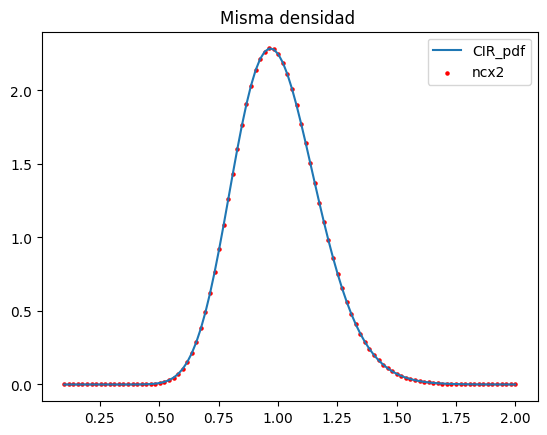

In [13]:
xxx = np.linspace(0.1, 2, 100)

c = 2*kappa / ((1-np.exp(-kappa*T))*sigma**2)
q = 2*kappa*theta / sigma**2 -1
u = c*X0*np.exp(-kappa*T) 
df = 2*q+2                       # parámetro K
nc = u*2                         # parámetro lambda

plt.plot(xxx, CIR_pdf(xxx, X0, T, kappa, theta, sigma), label="CIR_pdf")
plt.scatter(xxx, ss.ncx2.pdf(xxx, df, nc, scale=1/(2*c)), color = 'red', s=5, label="ncx2")
plt.legend(); plt.title("Misma densidad "); plt.show()

In [14]:
print(kappa, theta, sigma)
print(kappa_OLS, theta_OLS, sigma_OLS)


4 1 0.5
4.7128644281007945 1.0401635711658908 0.514361308780433


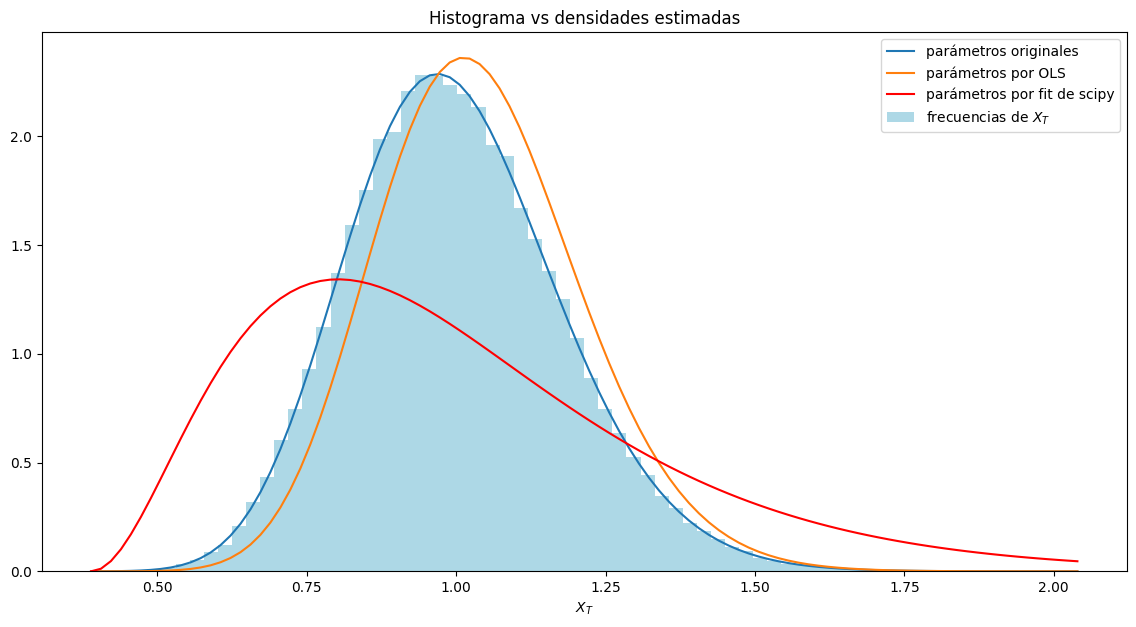

In [15]:
x = np.linspace(X_T.min(), X_T.max(), 100)
pdf_Chi2_fitted = ss.ncx2.pdf(x, *param_Chi2)             # densidad con los parámetros que dio el fit

plt.figure(figsize=(14,7))
plt.plot(x, CIR_pdf(x, X0, T, kappa, theta, sigma), label="parámetros originales")
plt.plot(x, CIR_pdf(x, X0, T, kappa_OLS, theta_OLS, sigma_OLS), label="parámetros por OLS")
plt.plot(x, pdf_Chi2_fitted, color='r', label="parámetros por fit de scipy")
plt.hist(X_T, density=True, bins=70, facecolor="LightBlue", label=r"frecuencias de $X_T$")
plt.legend(); plt.title("Histograma vs densidades estimadas"); plt.xlabel(r"$X_T$")
plt.show()

Observe que con `ncx2.fit(X_T)`, ajustamos la distribución en el tiempo $T$.

**¡¡Pero esto no es lo que sucede en la práctica!!**
En la práctica, cuando trabajamos con datos del mercado financiero, ¡solo tenemos 1 camino realizado! (solo tenemos una realización de $X_T$).
Además, no podemos usar `ncx2.fit` con la serie de retornos, porque los retornos no están distribuidos de manera idéntica.

¡El método OLS descrito anteriormente es el método correcto para usar! Una alternativa puede ser utilizar el método MLE, considerando la densidad de probabilidad condicional.


### Comentario

Si conocemos la densidad condicional, ¿por qué necesitamos resolver numéricamente el EDE? ¿Por qué no podemos simplemente generar variables aleatorias a partir de esta densidad?

**Bueno, podemos, y en algunas circunstancias es lo mejor que se puede hacer...**
Pero el proceso CIR se utiliza principalmente como modelo para la dinámica de la volatilidad en el modelo de Heston, donde el enfoque EDE es más fácil de implementar.

<a id='sec3.3'></a>
## Cambio de variable

Un buen truco para resolver el problema de los valores negativos es cambiar las variables. (este es un truco recurrente en las matemáticas financieras)

Consideremos la variable logarítmica:

$$  Y_t = \log X_t $$

La nueva variable $Y_t$ puede ser negativa cuando $0<X_t<1$.

Usando el lema de Itô obtemos que la EDE de $Y_t$ está dada por:

$$ dY_t = e^{-Y_t} \biggl[ \kappa (\theta - e^{Y_t}) - \frac{1}{2}\sigma^2 \biggr] dt + \sigma e^{-2 Y_t} dW_t $$

Usando el método de Euler-Maruyama, se puede discretizar como: 

$$ Y_{i+1} = Y_i + e^{-Y_i} \biggl[ \kappa (\theta - e^{Y_i}) - \frac{1}{2}\sigma^2 \biggr] \Delta t + \sigma e^{-2 Y_i} \Delta W_i.$$

Simulemos algunas trayectorias.

In [16]:
np.random.seed(seed=42) 

N = 200001        # time steps 
paths = 2         # number of paths 
T = 3
T_vec, dt = np.linspace(0,T,N, retstep=True ) 

kappa = 4 
theta = 1 
sigma = 0.5     
std_asy = np.sqrt( theta * sigma**2 /(2*kappa) )   

X0 = 2
Y0 = np.log(X0)

Y = np.zeros((paths,N))
Y[:,0] = Y0
W = ss.norm.rvs( loc=0, scale=np.sqrt(dt), size=(paths,N-1) )

for t in range(0,N-1):
    Y[:,t+1] = Y[:,t] + np.exp(-Y[:,t])*( kappa*(theta - np.exp(Y[:,t])) - 0.5*sigma**2 )*dt \
                                          + sigma * np.exp(-Y[:,t]/2) * W[:,t] 



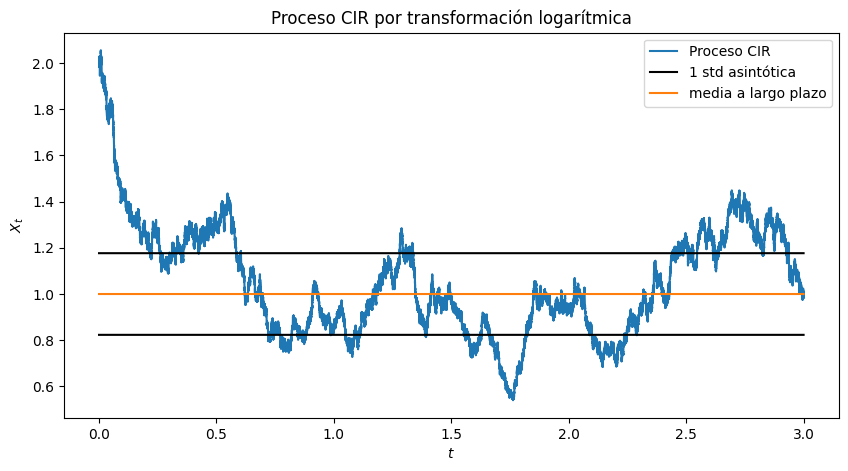

In [17]:
Y_T = Y[:,-1]    # valores de X_T 
Y_1 = Y[1,:]     # una trayectoria

plt.figure(figsize=(10,5))
plt.plot(T_vec, np.exp(Y_1), label="Proceso CIR")
plt.plot(T_vec, (theta + std_asy)*np.ones_like(T_vec), label="1 std asintótica", color="black" )
plt.plot(T_vec, (theta - std_asy)*np.ones_like(T_vec), color="black" )
plt.plot(T_vec, theta*np.ones_like(T_vec), label="media a largo plazo" )
plt.legend(loc="upper right"); plt.title("Proceso CIR por transformación logarítmica"); plt.xlabel(r"$t$")
plt.ylabel(r"$X_t$")
plt.show()

Como era de esperarse, la trayectoria se sigue viendo parecida a antes.
 
**¡Este podría ser el mejor enfoque teórico!**

Sin embargo, en la práctica, este no es el método perfecto. Puede tener varios problemas para valores pequeños de $N$.
Por ejemplo, como el algoritmo implica una función exponencial, puede generar números enormes e incluso NaN.

## Referencias

[1]  Cox, J.C., Ingersoll, J.E and Ross, S.A. A Theory of the Term Structure of Interest Rates.
Econometrica, Vol. 53, No. 2 (March, 1985)

# Proceso Ornstein-Uhlenbeck y aplicaciones


## Contenido
   - [Proceso Ornstein-Uhlenbeck](#sec1)
      - [Simulación](#sec1.1)
      - [Estimación de parámetros a partir de una trayectoria](#sec1.2)
      - [Tiempo esperado hasta alcanzar la media a largo plazo](#sec1.3)
   - [Valuación de bonos bajo el modelo de Vasicek](#sec2)



<a id='sec1'></a>
# Proceso OU 

El proceso [Ornstein-Uhlenbeck](https://en.wikipedia.org/wiki/Ornstein%E2%80%93Uhlenbeck_process) 
está descrito por la siguiente EDE: 

$$ dX_t = \kappa (\theta - X_t) dt + \sigma dW_t .$$

Donde los parámetros son:
- $\kappa > 0$:  velocidad de reversión a la media    
- $\theta \in \mathbb{R}$:  media a largo plazo  
- $\sigma > 0$:   volatilidad

Este proceso es gaussiano, markoviano y estacionario.

##### La EDE anterior se puede resolver explícitamente

Definamos el proceso $Y_t = X_t - \theta$ de manera que $dY_t = dX_t$.      
La EDE de $Y$ es:

$$ dY_t = - \kappa \, Y_t \, dt + \sigma \, dW_t .$$

Si consideramos la funciín: $f(t,y) = y e^{\kappa t}$.      
Sus derivadas son:

$$ \frac{\partial f}{\partial t} = y\, \kappa\, e^{\kappa t}  \quad \frac{\partial f}{\partial y} = e^{\kappa t} 
\quad \frac{\partial^2 f}{\partial y^2} = 0 .$$

Podemos usar la fórmula de Itô:

$$ \begin{aligned}
d( Y_t \, e^{\kappa t} ) &= \kappa \, Y_t\, e^{\kappa t}\, dt + e^{\kappa t}\, dY_t \\ 
                         &= \kappa \, Y_t\, e^{\kappa t}\, dt + e^{\kappa t}\, \biggl( - \kappa \, Y_t \, dt + \sigma \, dW_t \biggr) \\
                         &= e^{\kappa t} \sigma dW_t .
\end{aligned} $$

Por conveniencia, cambiamos la variable $t$ por $s$, e integramos en ambos lados en $[0,t]$:

$$ Y_t\, e^{\kappa t} - Y_0 = \int_0^t e^{\kappa s} \sigma dW_t .$$

Regresando al proceso original $X$ obtenemos la solución:

$$ X_t = \theta + (X_0 - \theta)e^{-\kappa t} + \int_0^t \sigma\, e^{\kappa (s-t)} dW_s .$$

### Momentos:

La **esperanza** de $X_t$ es:

$$ \begin{aligned}
\mathbb{E}[X_t] &= \mathbb{E}\biggl[ \theta + (X_0 - \theta)e^{-\kappa t} + \int_0^t \sigma\, e^{\kappa (s-t)} dW_s \biggr] \\
                &= \theta + (X_0 - \theta)e^{-\kappa t}    
\end{aligned}$$

donde, como la integral de Itô es martingala, $ \mathbb{E}\bigl[ \int_0^t \sigma\, e^{\kappa (s-t)} dW_s \bigr] = 0$.

La **covarianza** es:

$$ \begin{aligned}
\text{Cov}[X_s, X_t] &= \text{Cov}\biggl[ \int_0^s \sigma\, e^{\kappa (u-s)} dW_u \, , \, 
\int_0^t \sigma\, e^{\kappa (v-t)} dW_v \biggr] =  \mathbb{E}\biggl[ \int_0^s \sigma\, e^{\kappa (u-s)} dW_u 
\int_0^t \sigma\, e^{\kappa (v-t)} dW_v \biggr] \\
                &= \sigma^2 e^{-\kappa (s+t)}\, \mathbb{E}\biggl[ \int_0^s e^{\kappa u} dW_u 
\int_0^t e^{\kappa v} dW_v \biggr] \\
                &= \sigma^2 e^{-\kappa (s+t)}\, \mathbb{E}\biggl[ \biggl( \int_0^{\text{min}(t,s)} e^{\kappa u} dW_u  + \int_{\text{min}(t,s)}^{\text{max}(t,s)} e^{\kappa u} dW_u \biggr) \cdot 
\int_0^{\text{min}(t,s)} e^{\kappa v} dW_v \biggr] \\
                &= \sigma^2 e^{-\kappa (s+t)}\, \mathbb{E}\biggl[ \biggl( \int_0^{\text{min}(t,s)} e^{\kappa u}   dW_u \biggr)^2 \biggr] \\
                &= \sigma^2 e^{-\kappa (s+t)}\, \int_0^{\text{min}(t,s)} e^{2 \kappa u} du \; = \; \frac{\sigma^2}{2\kappa} e^{-\kappa (s+t)}\, \biggl( e^{2\kappa\, \text{min}(t,s)} - 1 \biggr)  \\
                &= \frac{\sigma^2}{2\kappa} \biggl( e^{-\kappa |t-s|} - e^{-\kappa (s+t)}\, \biggr),  
\end{aligned}$$

De manera que la **variaza** es: 

$$ \text{Var}[X_t] = \text{Cov}[X_t, X_t] = \frac{\sigma^2}{2\kappa} \biggl( 1- e^{-2 \kappa t} \biggr).$$

Cuando $t\to \infty$ obtenemos la **media asintótica**: $\theta$ y la **varianza asintótica**: $\frac{\sigma^2}{2\kappa}$.

<a id='sec1.1'></a>
## Simulación

Podemos discretizar la EDE usando el método de Euler-Maruyama, la cual está implementada en el siguiente código como comentario.

Otra posibilidad es generar directamente valores para la solución de la EDE, pues es una v.a. Normal.

$$ X_{n+1} = \theta + (X_n - \theta)e^{-\kappa \Delta t} + \sqrt{\frac{\sigma^2}{2\kappa} \bigl( 1- e^{-2 \kappa \Delta t} \bigr)} \; \epsilon_n $$ 

donde $\epsilon_n \sim \mathcal{N}(0,1)$.

In [18]:
np.random.seed(seed=42) 

N = 20000           # partición del tiempo
paths = 10000        # número de trayectorias
T = 5
T_vec, dt = np.linspace(0, T, N, retstep=True ) 

kappa = 3 
theta = 0.5 
sigma = 0.5     
std_asy = np.sqrt( sigma**2 /(2*kappa) )   

X0 = 2
X = np.zeros((paths,N))
X[:,0] = X0
W = ss.norm.rvs( loc=0, scale=1, size=(paths,N-1) )

# método de Euler Maruyama
#for t in range(0,N-1):
#    X[:,t+1] = X[:,t] + kappa*(theta - X[:,t])*dt + sigma * np.sqrt(dt) * W[:,t]

std_dt = np.sqrt( sigma**2 /(2*kappa) * (1-np.exp(-2*kappa*dt)) )
for t in range(0,N-1):
    X[:,t+1] = theta + np.exp(-kappa*dt)*(X[:,t]-theta) + std_dt * W[:,t]
    
X_T = X[:,-1]    # valores de X_T
X_1 = X[1,:]     # una trayectoria

#### Media y desviación estándar

Como tenemos la posibilidad de generar varias trayectorias, consideremos los valores en el tiempo $T$. Calculamos la media teórica y la desviación estándar y las comparamos con los valores obtenidos a partir de los datos:

In [19]:
mean_T = theta + np.exp(-kappa*T) * (X0-theta) 
std_T = np.sqrt( sigma**2 /(2*kappa) * (1-np.exp(-2*kappa*T)) )

param = ss.norm.fit(X_T)   # FIT from data
print(f"Media teórica={mean_T.round(6)} y std teórica={std_T.round(6)}")
print("Parámetros del fit: media={0:.6f}, std={1:.6f}".format(*param) )  # these are MLE parameters

Media teórica=0.5 y std teórica=0.204124
Parámetros del fit: media=0.496008, std=0.199831


#### Plot

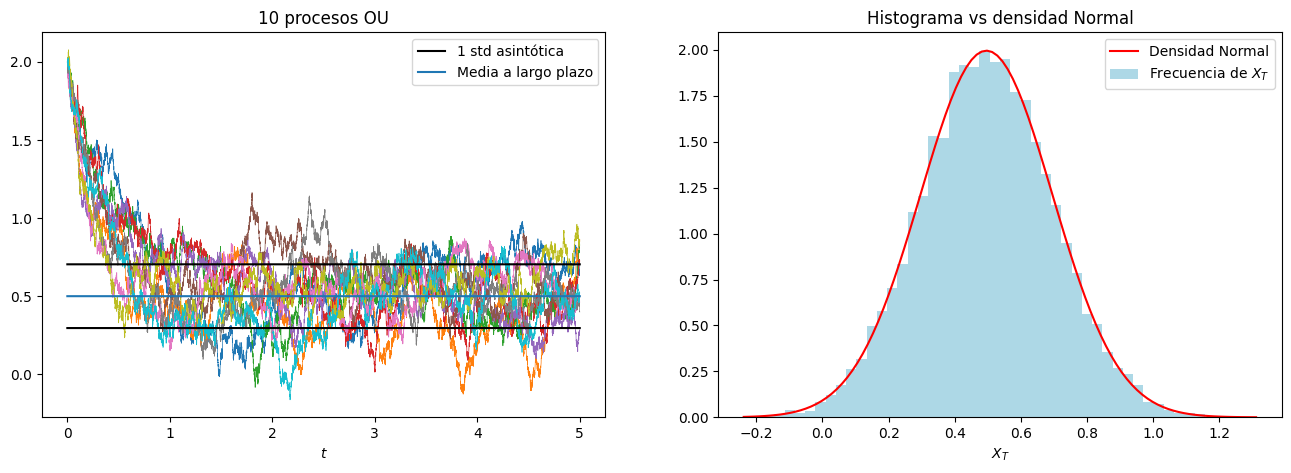

In [20]:
X_T = X[:,-1]    # valores de X_T
X_1 = X[1,:]     # una trayectoria

N_processes = 10    # número de trayectorias a graficar
x = np.linspace(X_T.min(), X_T.max(), 100)
pdf_fitted = ss.norm.pdf(x, *param)

fig = plt.figure(figsize=(16,5))
ax1 = fig.add_subplot(121); ax2 = fig.add_subplot(122)
ax1.plot(T_vec, X[:N_processes,:].T, linewidth=0.5)
ax1.plot(T_vec, (theta + std_asy)*np.ones_like(T_vec), label="1 std asintótica", color="black" )
ax1.plot(T_vec, (theta - std_asy)*np.ones_like(T_vec), color="black" )
ax1.plot(T_vec, theta*np.ones_like(T_vec), label="Media a largo plazo" )
ax1.legend(loc="upper right"); ax1.set_title(f"{N_processes} procesos OU"); ax1.set_xlabel(r"$t$")
ax2.plot(x, pdf_fitted, color='r', label="Densidad Normal")
ax2.hist(X_T, density=True, bins=50, facecolor="LightBlue", label=r"Frecuencia de $X_T$")
ax2.legend(); ax2.set_title("Histograma vs densidad Normal"); ax2.set_xlabel(r"$X_T$")
plt.show()

#### Covarianza

Podemos comparar también la covarianza teórica con la obtenida por las simulaciones.

In [21]:
n1 = 595; n2 = 600
t1 = n1*dt; t2 = n2*dt

cov_th = sigma**2 /(2*kappa) * (np.exp(-kappa*np.abs(t1-t2)) - np.exp(-kappa*(t1+t2)) )
print(f"Cov[X(t1), X(t2)] = {cov_th.round(4)} con t1 = {t1.round(4)} y t2 = {t2.round(4)}")
print(f"La covarianza de los datos es Cov[X(t1), X(t2)] = {np.cov( X[:,n1], X[:,n2] )[0,1].round(4)}") 

Cov[X(t1), X(t2)] = 0.0245 con t1 = 0.1488 y t2 = 0.15
La covarianza de los datos es Cov[X(t1), X(t2)] = 0.0247


<a id='sec1.2'></a>
## Estimación de parámetros a partir de una trayectoria

### Estimación por mínimos cuadrados

Podemos calcular $X_{t+\Delta t}$ y considerar el valor inical al tiempo $t$.

$$ \begin{aligned}
X_{t+\Delta t} &= \theta + (X_t - \theta)e^{-\kappa \Delta t} + \int_t^{t+\Delta t} \sigma\, e^{\kappa (s-t)} dW_s \\
               &= \theta \bigl( 1-e^{-\kappa \Delta t} \bigr) + e^{-\kappa \Delta t} X_t + \int_t^{t+\Delta t} \sigma\, e^{\kappa (s-t)} dW_s \\
               &= \alpha + \beta X_t + \epsilon_t
\end{aligned} $$

donde $\alpha = \theta \bigl( 1-e^{-\kappa \Delta t} \bigr)$, $\beta = e^{-\kappa \Delta t}$ y $\epsilon_t \sim \mathcal{N}\biggl( 0, \frac{\sigma^2}{2\kappa} \bigl( 1- e^{-2 \kappa \Delta t} \bigr)\biggr)$.

Entonces, podemos usar el método OLS para estimar $\alpha$, $\beta$ y $\sigma$.
Así, obtenemos los parámetros de las fórmulas:

$$ \kappa = - \frac{\log \beta}{\Delta t}, \quad \theta = \frac{\alpha}{1-\beta}, \quad 
\sigma = \text{Std}[\epsilon_t] \sqrt{ \frac{2\kappa}{1-\beta^2} }$$

The estimate of the parameters doesn't look very accurate. 

In [22]:
XX = X_1[:-1]
YY = X_1[1:]
beta, alpha, _, _, _ = ss.linregress(XX, YY)   # OLS
kappa_ols = - np.log(beta)/dt
theta_ols = alpha/(1-beta)
res = YY - beta * XX - alpha                   # residuales
std_resid = np.std(res, ddof=2)
sig_ols = std_resid * np.sqrt(2*kappa_ols/(1-beta**2))

print("OLS kappa = ", kappa_ols)
print("OLS theta = ", theta_ols)
print("OLS sigma = ", sig_ols)

#kappa = 3, theta = 0.5, sigma = 0.5

OLS kappa =  3.4448221867780426
OLS theta =  0.40273215093892223
OLS sigma =  0.49904604497283017


### Estimación por máxima verosimilitud

Sabemos que 
$$ X_{i+1} \sim \mathcal{N}\biggl( \theta \bigl( 1-e^{-\kappa \Delta t} \bigr) + e^{-\kappa \Delta t} X_i \, , \, \frac{\sigma^2}{2\kappa} \bigl( 1- e^{-2 \kappa \Delta t} \bigr)\biggr)$$

Defina os $\hat \theta^2 := \frac{\sigma^2}{2\kappa} \bigl( 1- e^{-2 \kappa \Delta t} \bigr)$.

En este punto es posible escribir la función de verosimilitud logarítmica e imponer la condición de que las derivadas de primer orden sean iguales a cero. Todos estos pasos se realizan en [1].
Aquí solo recuerdo las fórmulas finales:

$$ S_x = \sum_{i=1}^n X_{i-1} \quad S_y = \sum_{i=1}^n X_{i} \quad S_{xx} = \sum_{i=1}^n X_{i-1}^2 
\quad S_{xy} = \sum_{i=1}^n X_{i-1}X_{i} \quad S_{yy} = \sum_{i=1}^n X_{i}^2$$

Los parámetros son:

$$ \theta = \frac{S_y S_{xx} - S_x S_{xy}}{n(S_{xx}-S_{xy}) - (S_{x}^2 - S_{x} S_{y})} $$

$$ \kappa = - \frac{1}{\Delta t} \log \frac{S_{xy} - \theta S_{x} - \theta S_{y} +n\theta^2}{S_{xx} - 2\theta S_{x} +n \theta^2} $$

$$ 
\hat \theta^2 = \frac{1}{n} \biggl[ S_{yy} -2e^{-\kappa \Delta t} S_{xy} 
+ e^{-2 \kappa \Delta t} S{xx} -2\theta(1-e^{- \kappa \Delta t})(S_y - e^{- \kappa \Delta t}S_x) 
+n \theta^2(1-e^{- \kappa \Delta t})^2 \biggr] $$
$$ \theta^2 = \hat \theta^2 \frac{2\kappa}{1-e^{-2 \kappa \Delta t}} $$

Con el MLE obtenemos parámetros bastante similares a los obtenidos por OLS.

In [23]:
Sx = np.sum(XX)
Sy = np.sum(YY)
Sxx = XX @ XX
Sxy = XX @ YY
Syy = YY @ YY

theta_mle = (Sy*Sxx - Sx*Sxy) / (N*(Sxx-Sxy) - (Sx**2 - Sx*Sy) )
kappa_mle = -1/dt * np.log( (Sxy - theta_mle*Sx - theta_mle*Sy +N*theta_mle**2) 
                          / (Sxx - 2*theta_mle*Sx + N*theta_mle**2)  )
sigma2_hat = ( Syy -2*np.exp(-kappa_mle*dt)*Sxy + np.exp(-2*kappa_mle*dt)*Sxx - 2*theta_mle*
             (1-np.exp(-kappa_mle*dt))*(Sy-np.exp(-kappa_mle*dt)*Sx) + N*theta_mle**2 * 
              (1-np.exp(-kappa_mle*dt))**2 )/N
sigma_mle = np.sqrt(sigma2_hat * 2*kappa_mle / (1-np.exp(-2*kappa_mle*dt)))

In [24]:
print("kappa MLE = ", kappa_mle)
print("theta MLE = ", theta_mle)
print("sigma MLE = ", sigma_mle)
#kappa = 3, theta = 0.5, sigma = 0.5

kappa MLE =  3.44449612130116
theta MLE =  0.40270576102023375
sigma MLE =  0.4990086188977472


<a id='sec1.3'></a>
## Tiempo esperado para alcanzar la media a largo plazo

El cálculo de la densidad de tiempo de primera llegada a cierto nivel de un proceso de Ornstein-Uhlenbeck es un problema que lleva tiempo, que aún permanece abierto.
El tiempo de primera llegada de un proceso OU tiene muchas aplicaciones en matemáticas aplicadas, especialmente en finanzas matemáticas y para el diseño de estrategias trading.

Definamos el tiempo de primera llegada para el proceso OU:

$$ T_{A,C} = \inf\biggl\{ t\geq 0 \;: \; X_t = A \bigg| X_0 = C   \biggr\} $$

Para facilitar el problema, se considera la versión estandarizada con $\theta=0$, $\kappa=1$ y $\sigma^2=2$. 

$$ dX_t = - X_t dt + \sqrt{2} dW_t .$$

Podemos incluso simplificarlo más, usando $\sigma=1$.

Se obtiene la versión estandarizada con el siguiente cambio de variables:

$$ \bar t = \kappa t, \quad \bar X_t = \frac{\sqrt{2\kappa}}{\sigma}(X_t-\theta), \quad \bar C = \frac{\sqrt{2\kappa}}{\sigma}(C-\theta), \quad \bar A = \frac{\sqrt{2\kappa}}{\sigma}(A-\theta) $$

(abusando de la notación, le quitamos las barras a las constantes).    

Sea $f_{A,C}(t)$ la densidad de $T_{A,C}$. Para $A=0$, la densidad tiene la forma:

$$ f_{0,C}(t) = \sqrt{\frac{2}{\pi}} \frac{|C| e^{-t}}{(1-e^{-2t})^{3/2}} \exp\biggl[- \frac{C^2e^{-2t}}{2(1-e^{-2t})}  \biggr] $$

Gracias al cambio de variable, el tiempo esperado que le toma al proceso empezando en $X_0$ para llegar al nivel $\theta$, es igual al tiempo esperado (escalado) que le toma al proceso estandarizado llegar a $0$ partiendo de $\bar C$.

#### Podemos estimar este tiempo esperado numéricamente

In [25]:
theta

0.5

In [26]:
X.shape #10000 trayectorias
#20000 pasos en el tiempo

(10000, 20000)

In [27]:
X0

2

In [28]:
#primera vez que hay un true por renglón. 
#Si x0 está por encima de theta vemos el primer valor que lo cruzó hacia abajo
#Si x0=2 y theta=0.5 donde x esá por debajo
T_to_theta = np.argmax(X<=theta if (X0>theta) else X>=theta, axis=1)*dt
# tiempo de primera llegada a theta

In [29]:
np.argmax(X<=theta if (X0>theta) else X>=theta, axis=1)

array([4034, 2367, 5637, ..., 6182, 2662, 4287])

In [30]:
np.argmax(X<=theta if (X0>theta) else X>=theta, axis=1).shape

(10000,)

In [31]:
(X<=theta)[0][4033]

False

In [32]:
(X<=theta)[0][4034]

True

In [33]:
(X)[0][4033]

0.5187985464269819

In [34]:
(X)[0][4034]

0.4963474182385045

In [35]:
print(f"El tiempo esperado para llegar a theta partiendo de X0 es: {T_to_theta.mean()} con std : {ss.sem(T_to_theta)}" )
print("La std del tiempo de primera llegada a theta es:", T_to_theta.std() )

El tiempo esperado para llegar a theta partiendo de X0 es: 0.8885285764288215 con std : 0.003727638353230987
La std del tiempo de primera llegada a theta es: 0.3727451966653545


#### Podemos definir la densidad y el nuevo punto de inicio $C$

Para comparar con el histograma, necesitamos tomar en cuenta la escala de tiempo: $\kappa t$.     
Entonces la densidad se puede expresar como: $\kappa f_{0,C}(\kappa t)$.

We can now compute the theoretical mean and standard deviation:

In [36]:
def density_T_to_theta(t, C):
    return np.sqrt(2/np.pi) * np.abs(C)*np.exp(-t) \
            / (1-np.exp(-2*t))**(3/2) * np.exp(-( (C**2)*np.exp(-2*t)) / (2*(1-np.exp(-2*t))) )

In [37]:
C = (X0 - theta)*np.sqrt(2*kappa)/sigma     # nuevo punto inicial

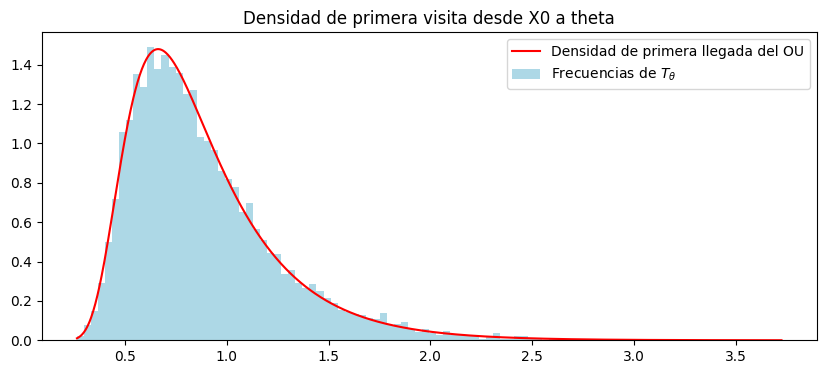

In [38]:
fig = plt.figure(figsize=(10,4))
x = np.linspace(T_to_theta.min(), T_to_theta.max(), 1000)
plt.plot(x, kappa*density_T_to_theta(kappa*x,C), color="red", label="Densidad de primera llegada del OU" )
plt.hist(T_to_theta, density=True, bins=100, facecolor="LightBlue", label=r"Frecuencias de $T_{\theta}$")
plt.title("Densidad de primera visita desde X0 a theta"); plt.legend(); plt.show()

In [39]:
from scipy.integrate import quad

In [40]:
theoretical_T = quad( lambda t : t*kappa*density_T_to_theta(kappa*t,C), 0, 1000)[0]
theoretical_std = np.sqrt(quad( lambda t : (t-theoretical_T)**2 *kappa*density_T_to_theta(kappa*t,C), 0,1000)[0])
print("Tiempo esperado de primera llegada teórico: ", theoretical_T)
print("Std del tiempo esperado de primera llegada teórica: ", theoretical_std)
#El tiempo esperado para llegar a theta partiendo de X0 es: 0.8885285764288215, que obtuvimos arriba

Tiempo esperado de primera llegada teórico:  0.8795633378038917
Std del tiempo esperado de primera llegada teórica:  0.36757135614701975


<a id='sec2'></a>
# Valuación de bonos bajo el modelo de Vasicek

El modelo de [Vasicek](https://en.wikipedia.org/wiki/Vasicek_model) describe la evolución del proceso de la tasa corta o instantanea $\{r_t\}_{t \in [0,T]}$ suponiendo que sigue un proceso OU bajo la medida neutral al riesgo (comúnmente denotada por $\mathbb{Q}$).

Entonces tenemos:

$$ dr_t = \kappa (\theta - r_t) dt + \sigma dW_t^{\mathbb{Q}} .$$

El precio de un **bono cero cupón** satisface la siguiente fórmula en términos de $r$:

$$ P(t,T) = \mathbb{E}^{\mathbb{Q}}\biggl[ e^{\int_t^T r_s \, ds} \; \bigg|\; \mathcal{F}_t \biggr]. $$

Luego de usar el lema de Itô y la fórmula de [Feynman-Kac](https://en.wikipedia.org/wiki/Feynman%E2%80%93Kac_formula), se puede ver que el precio del bono cupón cero satisface la siguiente EDP:

$$ \frac{\partial  P(t,r)}{\partial t}  
          + \kappa (\theta - r) \frac{\partial P(t,r)}{\partial r}
          + \frac{1}{2} \sigma^2 \frac{\partial^2  P(t,r)}{\partial r^2} - r  P(t,r)  = 0. $$
          
Con condiciones de frontera:

$$ P(T,r) = 1. $$


Siguiendo [2] (pag 59), podemos resolver de manera explícita esta EDP y obtener así que:

$$ P(t,T) = A(t,T) e^{-B(t,T) r_t} $$

donde 

$$ A(t,T) = exp\biggl[ \biggl(\theta - \frac{\sigma^2}{2\kappa^2}\biggr)(B(t,T)-T+t) - \frac{\sigma^2}{4\kappa} B(t,T)^2 \biggr] \quad \text{and} \quad 
B(t,T) = \frac{1}{\kappa} \biggl( 1 - e^{-\kappa (T-t)} \biggr) .$$

#### Closed formula:

In [59]:
X0,T

(2, 5)

In [42]:
B = 1/kappa * ( 1-np.exp(-kappa*T) )
A = np.exp( (theta - sigma**2/(2*kappa**2) ) * (B-T) - sigma**2/(4*kappa) * B**2  )
P = A * np.exp(-B * X0)
print("Precio del bono bajo el modelo de Vasicek: ", P)

Precio del bono bajo el modelo de Vasicek:  0.05299806665958418


#### Monte Carlo

In [43]:
X.shape

(10000, 20000)

In [44]:
X.mean(axis=1).shape

(10000,)

In [45]:
disc_factor = np.exp(- X.mean(axis=1)*T )
P_MC = np.mean( disc_factor )
st_err = ss.sem( disc_factor )
print(f"Precio del bono por MC bajo el modelo de Vasicek: {P_MC} con std alrededor del precio: {st_err}")

Precio del bono por MC bajo el modelo de Vasicek: 0.053296068049004955 con std alrededor del precio: 0.0001954549177016319


#### PDE

Otro método común para valuar derivados, es a partir de la EDP que surge del lema de Itô y luego de ocupar la fórmula de Feymann-Kac.

Podemos discretizar la EDP
usando el [esquema Upwind](https://en.wikipedia.org/wiki/Upwind_scheme):    

$$
 \frac{P^{n+1}_{i} -P^{n}_{i}}{\Delta t}  
          + \max \biggl( \kappa(\theta-r_i),\, 0 \biggr) \frac{P^{n}_{i+1} -P^{n}_{i}}{ \Delta r} 
          + \min \biggl( \kappa(\theta-r_i),\, 0 \biggr) \frac{P^{n}_{i} -P^{n}_{i-1}}{ \Delta r} 
          + \frac{1}{2} \sigma^2  \frac{P^{n}_{i+1} + P^{n}_{i-1} - 2 P^{n}_{i}}{\Delta r^2} 
          - r_i  P^{n}_i  = 0. 
$$

Por conveniencia de notación, escribiremos $\text{max}_i = \max \bigl( \kappa(\theta-r_i),\, 0 \bigr)$ y $\text{min}_i = \min \bigl( \kappa(\theta-r_i),\, 0 \bigr)$.     
De manera que podemos reescribir la ecuación de arriba como:

$$ \begin{aligned}
P^{n+1}_{i} =& \; P^{n}_{i-1} \biggl( \text{min}_i \frac{\Delta t}{\Delta r} -\frac{1}{2} \sigma^2 
\frac{\Delta t}{\Delta r^2} \biggr)  \\
             & + P^{n}_{i} \biggl( 1 + r_i \Delta t + \frac{\Delta t}{\Delta r}( \text{max}_i - \text{min}_i ) + \sigma^2 \frac{\Delta t}{\Delta r^2} \biggr) \\
             & + P^{n}_{i+1} \biggl( -\text{max}_i \frac{\Delta t}{\Delta r} -\frac{1}{2} \sigma^2 
\frac{\Delta t}{\Delta r^2} \biggr)
\end{aligned}$$

Dado $P^{n+1}$, podemos resolver para $P^{n}$.     
Para una mejor implementación se pueden agregar otras condiciones de frontera:

$$ P(t, r_{\text{min}}) = e^{-r_{\text{min}} (T-t)} \quad \text{y} \quad P(t, r_{\text{max}}) = e^{-r_{\text{max}} (T-t)}. $$

Aunque los valores que resultan son extremos, esto se puede mejorar usando una malla de discretización más fina.




In [46]:
from scipy import sparse
from scipy.sparse.linalg import spsolve


In [47]:
Nspace = 6000   # M partición del espacio
Ntime = 6000    # N partición temporal  
r_max = 3            # A2
r_min = -0.8         # A1
r, dr = np.linspace(r_min, r_max, Nspace, retstep=True)    # discretización espacial
T_array, Dt = np.linspace(0, T, Ntime, retstep=True)       # discretización temporal
Payoff = 1                                                 # payoff del bono

V = np.zeros((Nspace,Ntime))       # inicialización de la malla
offset = np.zeros(Nspace-2)        # vector que se usará para las condiciones de frontera 
V[:,-1] = Payoff                   # condiciones terminales, el bono siempre acaba en su payoff 
V[-1,:] = np.exp(- r[-1] * (T-T_array) )    # cota lateral, rmax
V[0,:] = np.exp(- r[0] * (T-T_array) )      # cota lateral, rmin

# construcción de la matriz tridiagonal D
sig2 = sigma*sigma; drr = dr * dr
max_part = np.maximum( kappa * (theta-r[1:-1]) , 0 )        # parte positiva del upwind
min_part = np.minimum( kappa * (theta-r[1:-1]) , 0 )        # parte negativa del upwind 
    
a = min_part * (Dt/dr)  - 0.5 * (Dt/drr) * sig2 
b = 1 + Dt*r[1:-1] + (Dt/drr)*sig2 + Dt/dr*(max_part - min_part)
c = -max_part * (Dt/dr) - 0.5 * (Dt/drr) * sig2 
    
a0 = a[0]; cM = c[-1]     # términos de frontera
aa = a[1:]; cc = c[:-1]   # diagonales superiores e inferiores
D = sparse.diags([aa, b, cc], [-1, 0, 1], shape=(Nspace-2, Nspace-2)).tocsc()     # matriz tridiagonal D

# cálculo backward
for n in range(Ntime-2,-1,-1):    
    offset[0] = a0 * V[0,n]
    offset[-1] = cM * V[-1,n]; 
    V[1:-1,n] = spsolve( D, (V[1:-1,n+1] - offset) )   #resuelve el sistema lineal generado por D

# El precio del bono dado el valor inicial X0
Price = np.interp(X0, r, V[:,0])
print("Precio del bono por EDP bajo el modelo de Vasicek es: ", Price)

Precio del bono por EDP bajo el modelo de Vasicek es:  0.05303018916704414


#### Plot

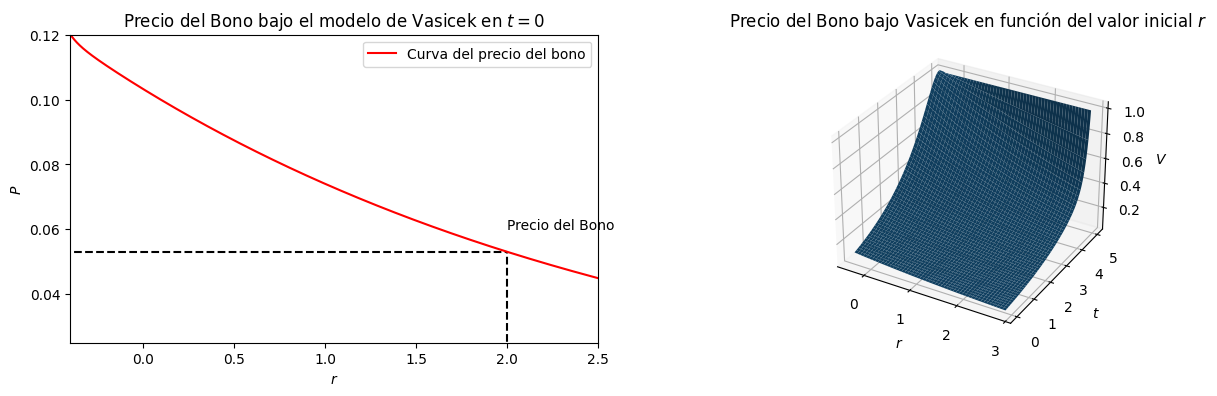

In [60]:
fig = plt.figure(figsize=(15,4))
ax1 = fig.add_subplot(121); ax2 = fig.add_subplot(122, projection='3d')

ax1.text(X0, 0.06, "Precio del Bono")
ax1.plot([X0, X0], [0, Price], 'k--'); ax1.plot([-0.5, X0], [Price, Price], 'k--')
ax1.plot(r, V[:,0], color='red',label="Curva del precio del bono")
ax1.set_xlim(-0.4,2.5); ax1.set_ylim(0.025,0.12)
ax1.set_xlabel(r"$r$"); ax1.set_ylabel(r"$P$"); ax1.legend(loc='upper right')
ax1.set_title(r"Precio del Bono bajo el modelo de Vasicek en $t=0$")

X_plt, Y_plt = np.meshgrid(T_array, r[700:-200])  # I consider [700:-200] to remove lateral boundary effects
ax2.plot_surface(Y_plt, X_plt, V[700:-200])
ax2.set_title(r"Precio del Bono bajo Vasicek en función del valor inicial $r$"); ax2.set_xlabel(r"$r$"); ax2.set_ylabel(r"$t$"); ax2.set_zlabel(r"$V$")
plt.show()

## References

[1] Thijs van den Berg, [Calibrating the Ornstein-Uhlenbeck(Vasicek) model](https://www.statisticshowto.com/wp-content/uploads/2016/01/Calibrating-the-Ornstein.pdf)

[2] Brigo and Mercurio, *Interest Rate Models - Theory and Practice: With Smile, Inflation and Credit*

[3] Robert J. Elliott , John Van Der Hoek & William P. Malcolm, *Pairs trading*, Quantitative Finance, (2007)

[4] Finch, S., [Ornstein–Uhlenbeck process](https://oeis.org/A249417/a249417.pdf), (2004).

[5] Alexander Lipton, Vadim Kaushansky, [On the First Hitting Time Density of an
Ornstein-Uhlenbeck Process](https://arxiv.org/pdf/1810.02390.pdf), (2018)

[6] L. M. Ricciardi and S. Sato, First-passage-time density and moments of the Ornstein-Uhlenbeck process, J. Appl. Probab. 25 (1988)

[7] Shumway, R.H. and Stoffer, D.S., *An approach to time series smoothing and forecasting using the EM algorithm*, Journal of Time Series, (1982)

[8] Cartea, A., Jaimungal, S., and Peñalva, J., *Algorithmic and high frequency trading*. Cambridge University Press, (2015)

[9] Paul Wilmott, *Paul Wilmott on quantitative finance*, (2006)

# Modelo Hull-White

El modelo Hull-White es un modelo de tasa corta que generaliza al modelo Vasicek. Pero de manera que sea capaz de adecuarse a la estructura temporal de tasas de interés, pues en general la media a largo plazo va cambiando conforme pasa el tiempo.

El primer modelo de Hull-White fue etiquetado por John C. Hull y Alan White en 1990.

Usaremos la libería de Quantlib (creada por Luigi Ballabio y muy utilizada en áreas cuantitativas) para las simulaciones de trayectorias bajo este modelo. 

El modelo más sencillo es el Hull-White de un factor, cuya EDE es la siguiente:

$$ dr_t = \left( \theta(t) - \alpha(t)r_t \right)dt + \sigma(t)dW_t. $$

Dependiendo de la bibliografía a veces suelen referirse a dicho modelo como Hull-White o como Vasicek extendido, dependiendo de que parámetros son dependientes del tiempo.

- Si $\theta$ depende del tiempo, suelen referirse a este modelo como Hull-White.
- Si tanto $\theta$ como $\alpha$ dependen del tiempo, suelen referirse a este modelo como Vasicek extendido.

Siguiendo de manera análoga los pasos que nos permitieron resolver la tasa en el modelo Vasicek, en este caso tenemos que para cuando $\theta$ depende del tiempo:

$$ r_t = e^{-\alpha t}r_0 + \int_0^t e^{\alpha(s-t)}\theta(s)ds + \sigma e^{-\alpha t}\int_0^t e^{\alpha u}dW_u, $$

que también tiene distribución Normal, pero con parámetros:

$$
\begin{eqnarray}
    \mathbb{E}(r_t) &=& e^{-\alpha t}r_0 + \int_0^t e^{\alpha(s-t)}\theta(s)ds\\
    Var(r_t) &=& \frac{\sigma^2}{2\alpha}(1- e^{-2\alpha t})
\end{eqnarray}
$$

In [49]:
#pip install Quantlib

In [65]:
import QuantLib as ql
import matplotlib.pyplot as plt
import numpy as np
#%matplotlib inline

https://quantlib-python-docs.readthedocs.io/en/latest/

In [70]:
#Las variables $\alpha$ y $\sigma$ son las constantes que definen el modelo Hull-White
sigma = 0.1 
a = 0.1
# Discretizamos un lapso de treinta años en intervalos de 360.
timestep = 360
length = 30 
#$\theta$ estará definida por la estructura temporal de tasas de interés (que por practicidad consideraremos constante)
forward_rate = 0.05 
day_count = ql.Thirty360(ql.Thirty360.BondBasis)
todays_date = ql.Date(3, 8, 2023)

In [71]:

ql.Settings.instance().evaluationDate = todays_date
# Usaremos una estructura temporal de tasa de interés constante como entrada para simplificar.
spot_curve = ql.FlatForward(todays_date, ql.QuoteHandle(ql.SimpleQuote(forward_rate)), day_count)
# Se puede intercambiar con otra estructura de términos aquí.
spot_curve_handle = ql.YieldTermStructureHandle(spot_curve) 
# definimos el proceso HW de la quantlib, esto es una instancia de dicho proceso
hw_process = ql.HullWhiteProcess(spot_curve_handle, a, sigma)
# para generar trayectorias, se generan los números pseudoaleatorios que se ocupan para simular trayectorias
rng = ql.GaussianRandomSequenceGenerator(ql.UniformRandomSequenceGenerator(timestep, ql.UniformRandomGenerator()))
seq = ql.GaussianPathGenerator(hw_process, length, timestep, rng, False)


In [72]:
def generate_paths(num_paths, timestep):
    arr = np.zeros((num_paths, timestep+1))
    for i in range(num_paths):
        sample_path = seq.next()
        path = sample_path.value()
        time = [path.time(j) for j in range(len(path))]
        value = [path[j] for j in range(len(path))]
        arr[i, :] = np.array(value)
    return np.array(time), arr

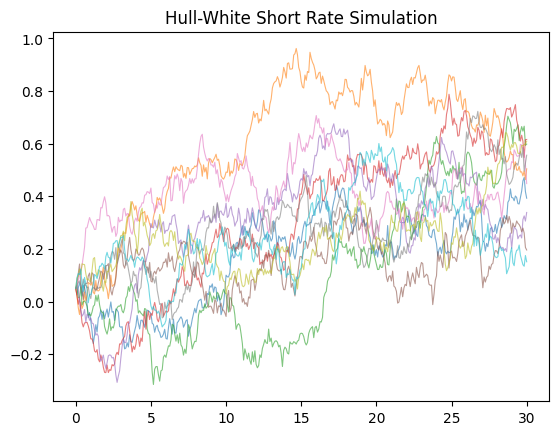

In [73]:
num_paths = 10
time, paths = generate_paths(num_paths, timestep)
for i in range(num_paths):
    plt.plot(time, paths[i, :], lw=0.8, alpha=0.6)
plt.title("Hull-White Short Rate Simulation")
plt.show()

In [82]:
num_paths = 2000
time, paths = generate_paths(num_paths, timestep)

Podemos comparar la esperanza y la varianza teóricas (líneas azules) con las que da la simulación (líneas rojas).

[]

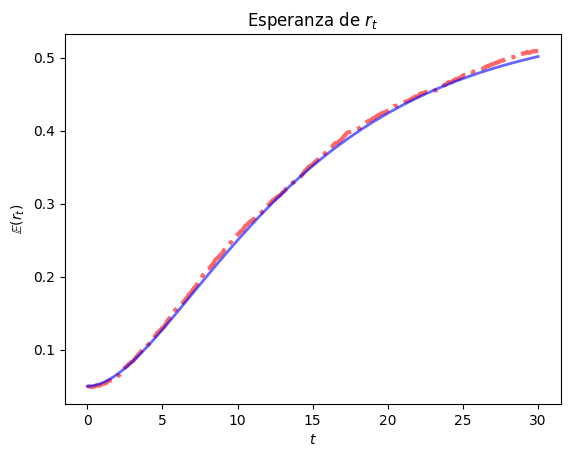

In [83]:
def alpha(forward, sigma, a, t):
    return forward + 0.5* np.power(sigma/a*(1.0 - np.exp(-a*t)), 2)

avg = [np.mean(paths[:, i]) for i in range(timestep+1)]
plt.plot(time, avg, "r-.", lw=3, alpha=0.6)
plt.plot(time,alpha(forward_rate, sigma, a, time), "b-", lw=2, alpha=0.6)
plt.xlabel(r"$t$")
plt.ylabel(r"$\mathbb{E}(r_t)$")
plt.title(r"Esperanza de $r_t$")
plt.plot()

[]

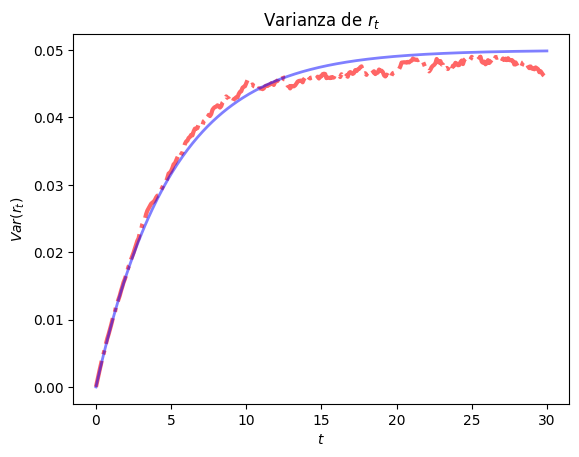

In [84]:
vol = [np.var(paths[:, i]) for i in range(timestep+1)]
plt.plot(time, vol, "r-.", lw=3, alpha=0.6)
plt.plot(time,sigma*sigma/(2*a)*(1.0-np.exp(-2.0*a*np.array(time))), "b-", lw=2, alpha=0.5)
plt.xlabel(r"$t$")
plt.ylabel(r"$Var(r_t)$")
plt.title(r"Varianza de $r_t$")
plt.plot()

# Consideraciones Adicionales
El modelo de Hull-White es un modelo de interés de un solo factor que se utiliza para cotizar derivados de tasas de interés. El modelo de Hull-White supone que las tasas cortas tienen una distribución Normal y que las tasas cortas presentan reversión a la media. Por lo tanto, es probable que la volatilidad sea baja cuando las tasas a corto plazo estén cerca de cero, lo que se refleja en una mayor reversión a la media en el modelo.

De la misma manera en que el modelo Hull-White extiende el modelo Vasicek, en el modelo Cox-Ingersoll-Ross (CIR) también se pueden considerar parámetros dependientes del tiempo para permitir una mejor calibración.

El modelo de Hull-White calcula el precio de un valor derivado como una función de la curva de rendimiento completa en lugar de una única tasa.

Un derivado de tasa de interés es un instrumento financiero cuyo valor está vinculado a los movimientos de una tasa o tasas de interés. Los derivados de tasas de interés suelen utilizarse como cobertura por parte de inversores institucionales, bancos, empresas e individuos para protegerse frente a cambios en las tasas de interés del mercado, pero también pueden utilizarse para aumentar o refinar el perfil de riesgo del titular o para especular sobre movimientos de tasas. Estos pueden incluir límites máximos y mínimos para las tasas de interés.

Las inversiones cuyos valores dependen de las tasas de interés, como las opciones sobre bonos, han ganado popularidad a medida que los sistemas financieros se han vuelto más sofisticados. Determinar el valor de estas inversiones a menudo implicaba el uso de diferentes modelos, y cada modelo tenía su propio conjunto de supuestos. 

A diferencia del modelo Hull-White, que usa la tasa corta instantánea, existen otros modelos: 
- Heath-Jarrow-Morton (HJM), que modela la tasa forward instantánea 
- Brace-Gatarek-Musiela (BGM) solo usa tasas que son observables; es decir, tasas LIBOR a plazo. 
- LIBOR o SWAP Market Model (LMM o SMM), modela las tasas Libor o tasas Par swap de mercado, asignándoles una dinámica dada por un sistema de EDE, donde se modela la correlación entre estas tasas.